Загрузка датасета taxis...
Исходный размер датасета: (6433, 14)

Первые 5 строк:
               pickup             dropoff  passengers  distance  fare   tip  \
0 2019-03-23 20:21:09 2019-03-23 20:27:24           1      1.60   7.0  2.15   
1 2019-03-04 16:11:55 2019-03-04 16:19:00           1      0.79   5.0  0.00   
2 2019-03-27 17:53:01 2019-03-27 18:00:25           1      1.37   7.5  2.36   
3 2019-03-10 01:23:59 2019-03-10 01:49:51           1      7.70  27.0  6.15   
4 2019-03-30 13:27:42 2019-03-30 13:37:14           3      2.16   9.0  1.10   

   tolls  total   color      payment            pickup_zone  \
0    0.0  12.95  yellow  credit card        Lenox Hill West   
1    0.0   9.30  yellow         cash  Upper West Side South   
2    0.0  14.16  yellow  credit card          Alphabet City   
3    0.0  36.95  yellow  credit card              Hudson Sq   
4    0.0  13.40  yellow  credit card           Midtown East   

            dropoff_zone pickup_borough dropoff_borough  
0    UN

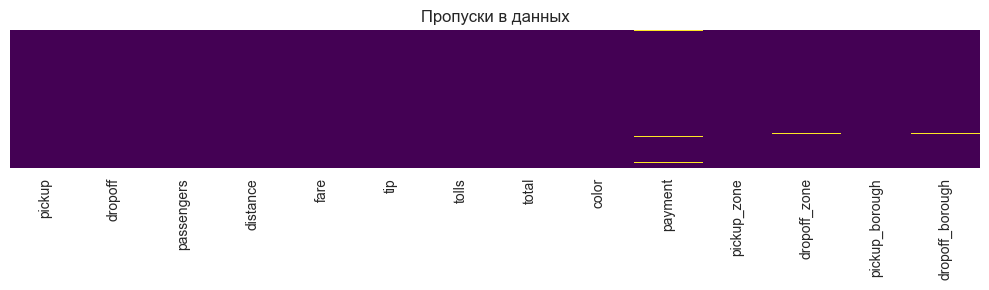


Количество дубликатов: 0
После удаления дубликатов: (6433, 14)

Заполнение пропусков:
  color: заполнено модой 'yellow'
  payment: заполнено модой 'credit card'
  pickup_zone: заполнено модой 'Midtown Center'
  dropoff_zone: заполнено модой 'Upper East Side North'
  pickup_borough: заполнено модой 'Manhattan'
  dropoff_borough: заполнено модой 'Manhattan'

Пропуски после очистки: 0

Обработка выбросов методом IQR:
  distance: выбросов 734 (11.4%)
  fare: выбросов 592 (9.2%)
  tip: выбросов 280 (4.4%)
  tolls: выбросов 350 (5.4%)
  total: выбросов 600 (9.3%)

Размер очищенного датасета: (6433, 14)

2. ОПИСАТЕЛЬНАЯ СТАТИСТИКА

Описательная статистика категориальных переменных:

color:
color
yellow    5451
green      982
Name: count, dtype: int64

payment:
payment
credit card    4621
cash           1812
Name: count, dtype: int64

pickup_zone:
pickup_zone
Midtown Center                  256
Upper East Side South           211
Penn Station/Madison Sq West    210
Clinton East               

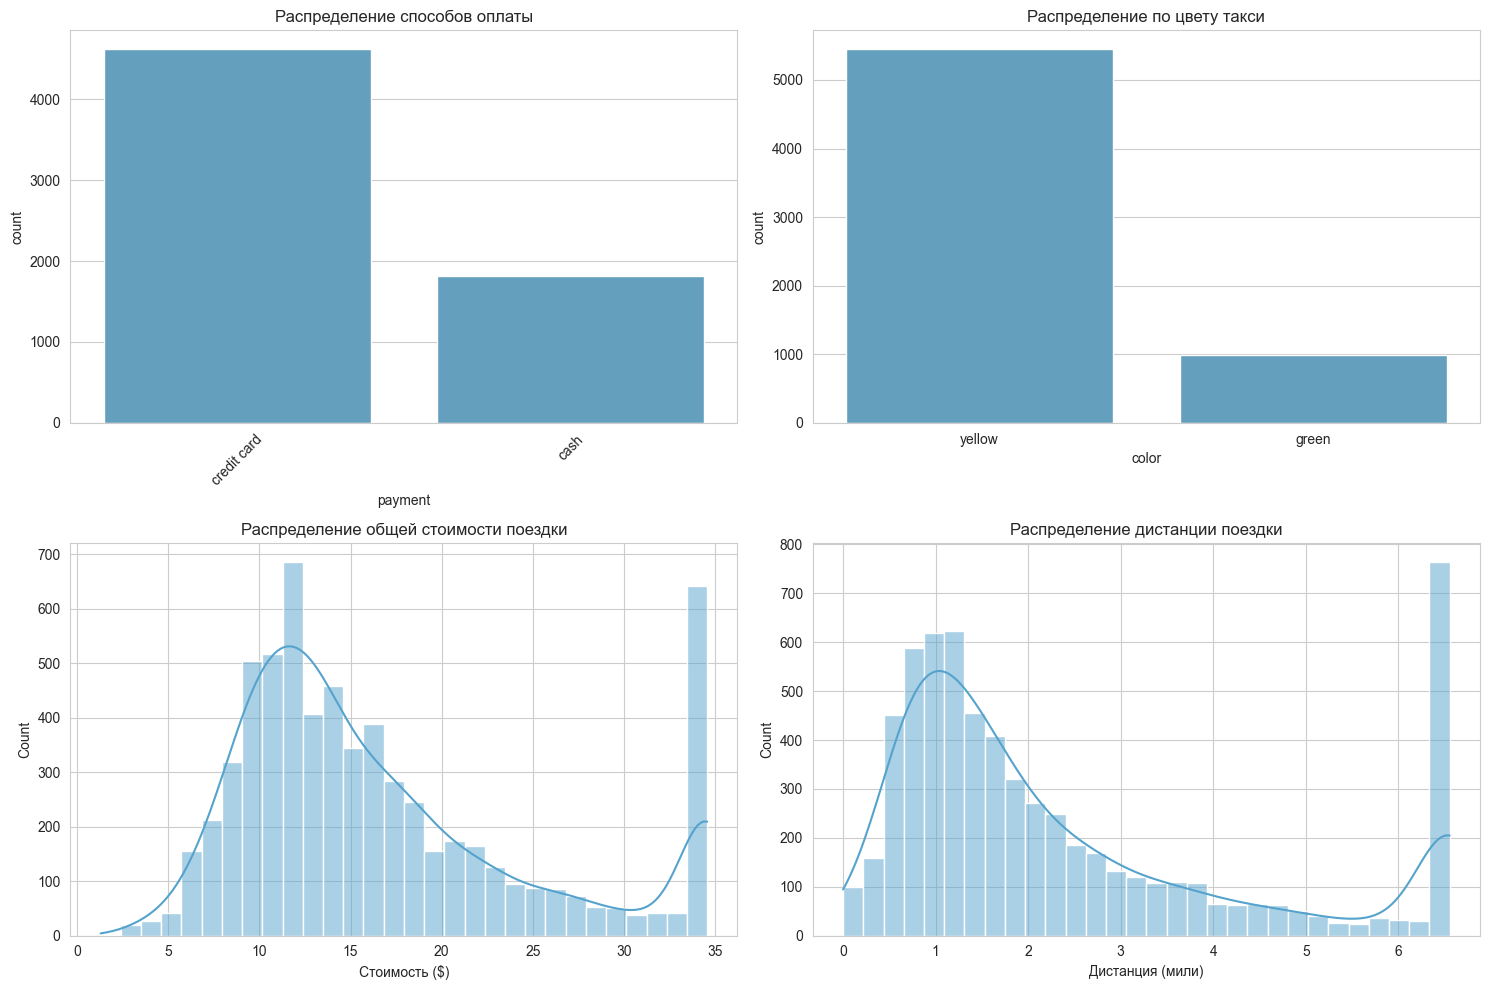

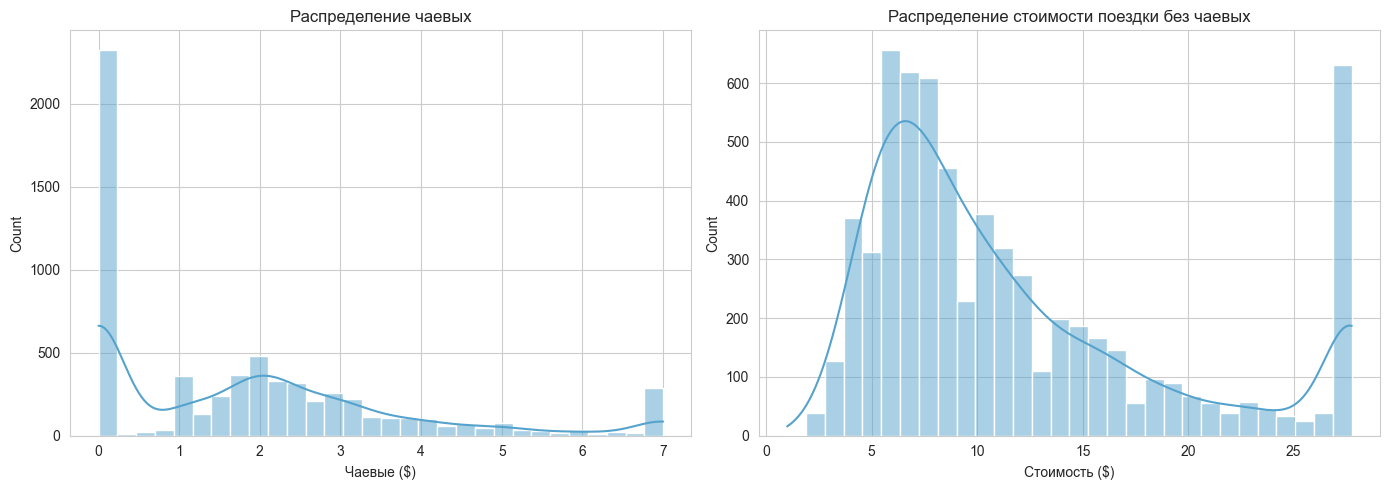


4. ИССЛЕДОВАНИЕ СВЯЗЕЙ

Матрица корреляций числовых переменных:
          distance      fare       tip  tolls     total
distance  1.000000  0.941214  0.406800    NaN  0.911732
fare      0.941214  1.000000  0.430519    NaN  0.969975
tip       0.406800  0.430519  1.000000    NaN  0.573821
tolls          NaN       NaN       NaN    NaN       NaN
total     0.911732  0.969975  0.573821    NaN  1.000000


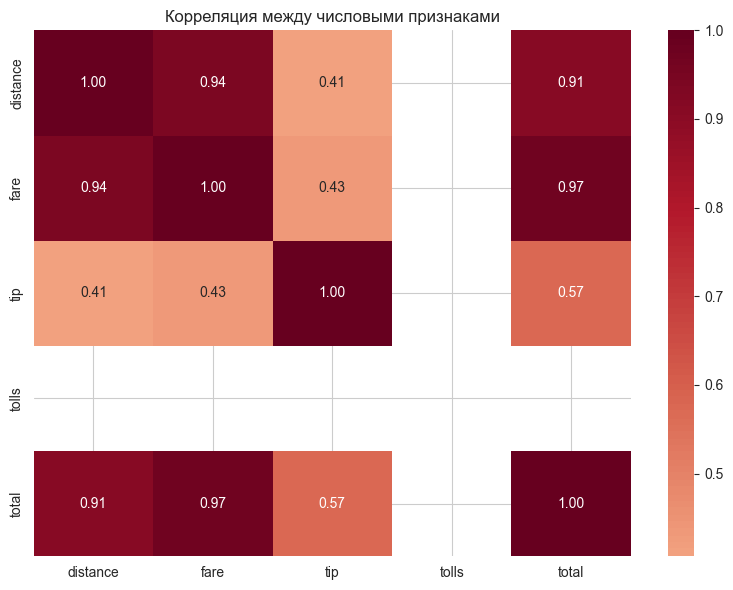

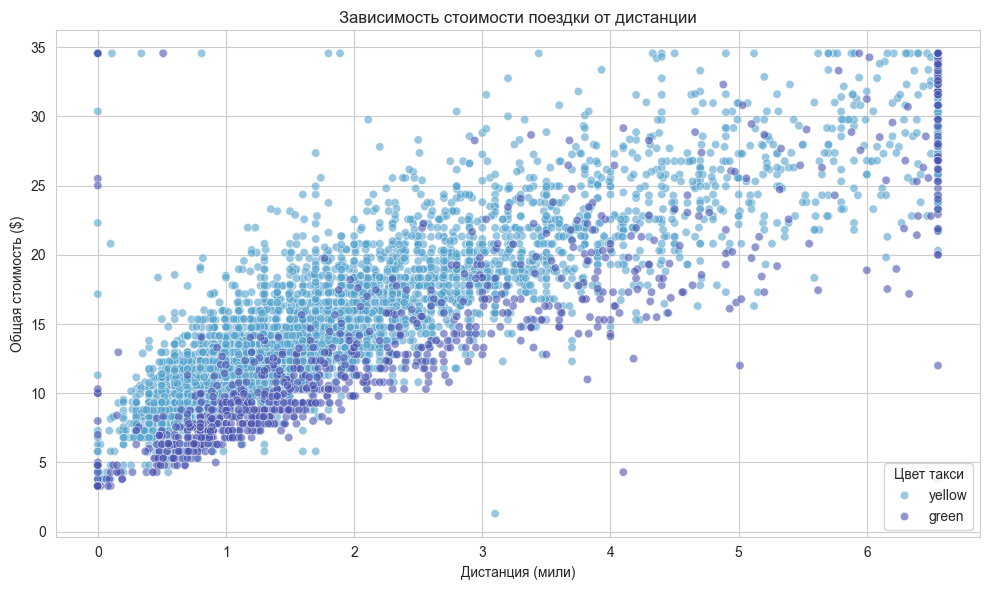

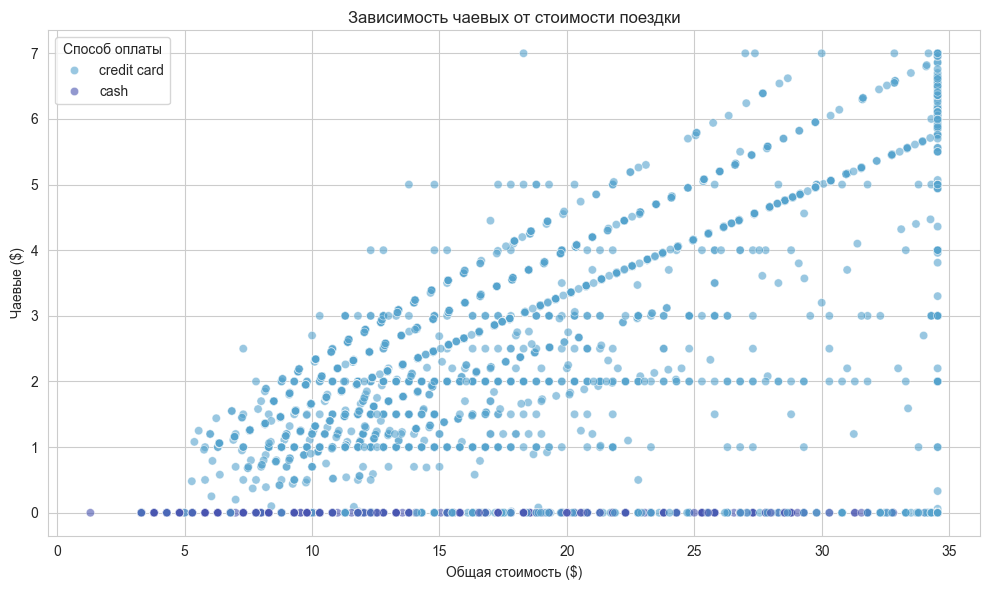


5. ГРУППИРОВКА ДАННЫХ

Медианная сумма чаевых по цвету такси:
color
green     0.00
yellow    1.95
Name: tip, dtype: float64

Средняя стоимость поездки по районам посадки (топ-10):
                 mean  count  median
pickup_borough                      
Queens          22.56    657   23.80
Bronx           19.77     99   16.80
Brooklyn        17.35    383   14.69
Manhattan       15.90   5294   13.80

Средняя стоимость и чаевые по способу оплаты:
             total          tip       
              mean median  mean median
payment                               
cash         13.68  11.30  0.00    0.0
credit card  17.92  15.35  2.55    2.2

6. ДОПОЛНИТЕЛЬНЫЕ ВИЗУАЛИЗАЦИИ


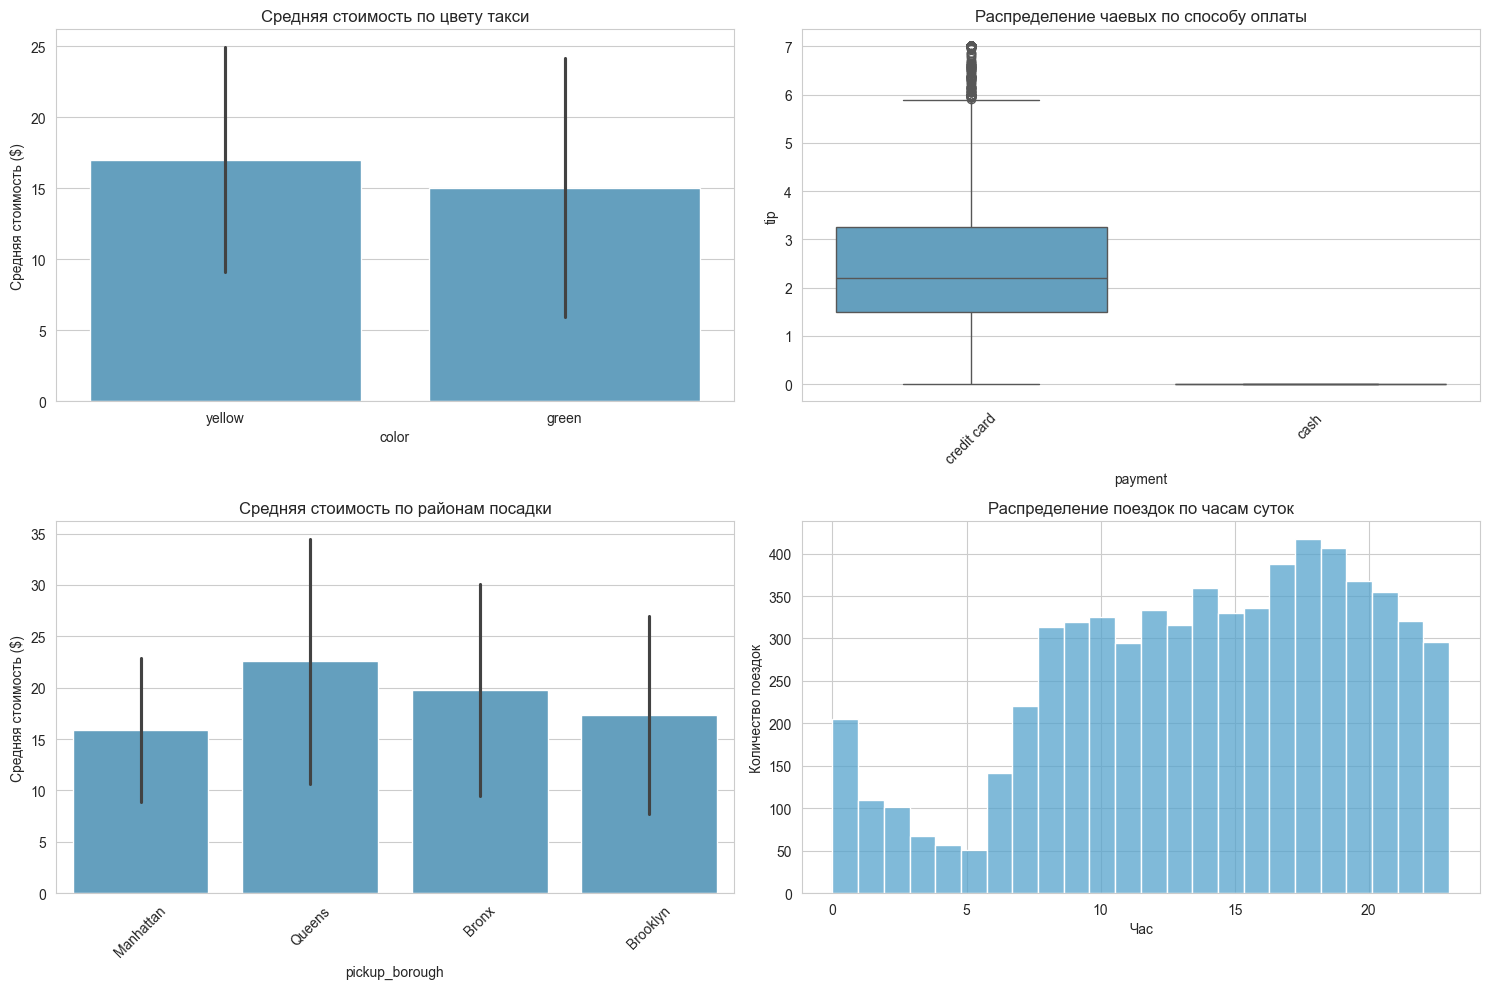


ГЛАВНЫЕ ВЫВОДЫ РАЗВЕДОТЕЛЬНОГО АНАЛИЗА

1. КАЧЕСТВО ДАННЫХ:
   - Исходный размер: 6433 строк
   - Удалено дубликатов: 0
   - Обработаны пропуски в 186 ячейках
   - Выбросы обработаны методом IQR (замена на границы)

2. РАСПРЕДЕЛЕНИЯ:
   - Основная масса поездок: стоимость до $25, дистанция до 5 миль
   - Кредитные карты — самый популярный способ оплаты
   - Желтые такси доминируют (около 70%)

3. КОРРЕЛЯЦИИ:
   - distance ↔ total: 0.91 (очень сильная)
   - total ↔ fare: 0.97 (очень сильная)
   - tip ↔ total: 0.57 (умеренная)

4. ГРУППОВЫЕ АНАЛИЗЫ:
   - Желтые такси: медиана чаевых $1.95
   - Queens: самый дорогой район посадки ($22.56)
   - Оплата картой: средняя стоимость $17.92
   - Оплата наличными: средняя стоимость $13.68

5. БИЗНЕС-ВЫВОДЫ:
   - Основной фокус: желтые такси в Manhattan
   - Пик поездок: вечерние часы (17-19)
   - Продвигать оплату картой (основной способ)


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('default')
sns.set_style('whitegrid')
sns.set_palette(sns.color_palette("icefire"))
pd.set_option('display.max_columns', None)

# Загружаем датасет такси из seaborn
print("Загрузка датасета taxis...")
df = sns.load_dataset('taxis')

print("Исходный размер датасета:", df.shape)
print("\nПервые 5 строк:")
print(df.head())

# ============================================================
# 1. ОЧИСТКА ДАННЫХ
# ============================================================

print("\n" + "="*60)
print("1. ОЧИСТКА ДАННЫХ")
print("="*60)

print("\nТипы данных и пропуски:")
df.info()

print("\nКоличество пропусков по столбцам:")
print(df.isnull().sum())

# Визуализация пропусков
plt.figure(figsize=(10, 3))
sns.heatmap(df.isnull(), cbar=False, yticklabels=False, cmap='viridis')
plt.title("Пропуски в данных")
plt.tight_layout()
plt.show()

print("\nКоличество дубликатов:", df.duplicated().sum())
df_clean = df.drop_duplicates().reset_index(drop=True)
print("После удаления дубликатов:", df_clean.shape)

# Заполнение пропусков
print("\nЗаполнение пропусков:")
for col in df_clean.columns:
    if df_clean[col].dtype == 'object':
        mode_val = df_clean[col].mode()
        if len(mode_val) > 0:
            df_clean[col] = df_clean[col].fillna(mode_val[0])
            print(f"  {col}: заполнено модой '{mode_val[0]}'")
        else:
            df_clean[col] = df_clean[col].fillna('Unknown')
    elif pd.api.types.is_numeric_dtype(df_clean[col]):
        df_clean[col] = df_clean[col].fillna(df_clean[col].median())

print("\nПропуски после очистки:", df_clean.isnull().sum().sum())

# Обработка выбросов для числовых переменных
num_cols = ['distance', 'fare', 'tip', 'tolls', 'total']

print("\nОбработка выбросов методом IQR:")
for col in num_cols:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    outlier_count = ((df_clean[col] < lower) | (df_clean[col] > upper)).sum()
    print(f"  {col}: выбросов {outlier_count} ({(outlier_count/len(df_clean))*100:.1f}%)")

    # Заменяем выбросы границами
    df_clean[col] = df_clean[col].clip(lower, upper)

print("\nРазмер очищенного датасета:", df_clean.shape)

# ============================================================
# 2. ОПИСАТЕЛЬНАЯ СТАТИСТИКА
# ============================================================

print("\n" + "="*60)
print("2. ОПИСАТЕЛЬНАЯ СТАТИСТИКА")
print("="*60)

print("\nОписательная статистика категориальных переменных:")
cat_cols = df_clean.select_dtypes(include=['object', 'category']).columns.tolist()
for col in cat_cols:
    print(f"\n{col}:")
    print(df_clean[col].value_counts().head(5))

print("\nОписательная статистика числовых переменных:")
print(df_clean[num_cols].describe())

# ============================================================
# 3. ВИЗУАЛИЗАЦИЯ РАСПРЕДЕЛЕНИЙ
# ============================================================

print("\n" + "="*60)
print("3. ВИЗУАЛИЗАЦИЯ РАСПРЕДЕЛЕНИЙ")
print("="*60)

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Гистограммы категориальных переменных
sns.countplot(data=df_clean, x='payment', ax=axes[0,0])
axes[0,0].set_title('Распределение способов оплаты')
axes[0,0].tick_params(axis='x', rotation=45)

sns.countplot(data=df_clean, x='color', ax=axes[0,1])
axes[0,1].set_title('Распределение по цвету такси')

# Гистограммы числовых переменных
sns.histplot(data=df_clean, x='total', bins=30, kde=True, ax=axes[1,0])
axes[1,0].set_title('Распределение общей стоимости поездки')
axes[1,0].set_xlabel('Стоимость ($)')

sns.histplot(data=df_clean, x='distance', bins=30, kde=True, ax=axes[1,1])
axes[1,1].set_title('Распределение дистанции поездки')
axes[1,1].set_xlabel('Дистанция (мили)')

plt.tight_layout()
plt.show()

# Дополнительные гистограммы для tip и fare
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(data=df_clean, x='tip', bins=30, kde=True, ax=axes[0])
axes[0].set_title('Распределение чаевых')
axes[0].set_xlabel('Чаевые ($)')
sns.histplot(data=df_clean, x='fare', bins=30, kde=True, ax=axes[1])
axes[1].set_title('Распределение стоимости поездки без чаевых')
axes[1].set_xlabel('Стоимость ($)')
plt.tight_layout()
plt.show()

# ============================================================
# 4. ИССЛЕДОВАНИЕ СВЯЗЕЙ
# ============================================================

print("\n" + "="*60)
print("4. ИССЛЕДОВАНИЕ СВЯЗЕЙ")
print("="*60)

print("\nМатрица корреляций числовых переменных:")
corr_matrix = df_clean[num_cols].corr()
print(corr_matrix)

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='RdBu_r', center=0, fmt='.2f')
plt.title('Корреляция между числовыми признаками')
plt.tight_layout()
plt.show()

# Диаграмма рассеяния: стоимость vs дистанция
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_clean, x='distance', y='total', hue='color', alpha=0.6)
plt.title('Зависимость стоимости поездки от дистанции')
plt.xlabel('Дистанция (мили)')
plt.ylabel('Общая стоимость ($)')
plt.legend(title='Цвет такси')
plt.tight_layout()
plt.show()

# Диаграмма рассеяния: чаевые vs стоимость
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_clean, x='total', y='tip', hue='payment', alpha=0.6)
plt.title('Зависимость чаевых от стоимости поездки')
plt.xlabel('Общая стоимость ($)')
plt.ylabel('Чаевые ($)')
plt.legend(title='Способ оплаты')
plt.tight_layout()
plt.show()

# ============================================================
# 5. ГРУППИРОВКА ДАННЫХ (groupby)
# ============================================================

print("\n" + "="*60)
print("5. ГРУППИРОВКА ДАННЫХ")
print("="*60)

print("\nМедианная сумма чаевых по цвету такси:")
tip_by_color = df_clean.groupby('color')['tip'].median()
print(tip_by_color)

print("\nСредняя стоимость поездки по районам посадки (топ-10):")
borough_stats = (
    df_clean.groupby('pickup_borough')['total']
    .agg(['mean', 'count', 'median'])
    .round(2)
    .sort_values('mean', ascending=False)
)
print(borough_stats.head(10))

print("\nСредняя стоимость и чаевые по способу оплаты:")
payment_stats = (
    df_clean.groupby('payment')[['total', 'tip']]
    .agg(['mean', 'median'])
    .round(2)
)
print(payment_stats)

# ============================================================
# 6. ДОПОЛНИТЕЛЬНЫЕ ВИЗУАЛИЗАЦИИ
# ============================================================

print("\n" + "="*60)
print("6. ДОПОЛНИТЕЛЬНЫЕ ВИЗУАЛИЗАЦИИ")
print("="*60)

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Средняя стоимость по цвету такси
sns.barplot(data=df_clean, x='color', y='total', ax=axes[0,0], errorbar='sd')
axes[0,0].set_title('Средняя стоимость по цвету такси')
axes[0,0].set_ylabel('Средняя стоимость ($)')

# Чаевые по способу оплаты
sns.boxplot(data=df_clean, x='payment', y='tip', ax=axes[0,1])
axes[0,1].set_title('Распределение чаевых по способу оплаты')
axes[0,1].tick_params(axis='x', rotation=45)

# Стоимость поездки по районам
top_boroughs = df_clean['pickup_borough'].value_counts().head(6).index
sns.barplot(data=df_clean[df_clean['pickup_borough'].isin(top_boroughs)],
            x='pickup_borough', y='total', ax=axes[1,0], errorbar='sd')
axes[1,0].set_title('Средняя стоимость по районам посадки')
axes[1,0].tick_params(axis='x', rotation=45)
axes[1,0].set_ylabel('Средняя стоимость ($)')

# Количество поездок по часам (из datetime)
df_clean['pickup_hour'] = pd.to_datetime(df_clean['pickup']).dt.hour
sns.histplot(data=df_clean, x='pickup_hour', bins=24, ax=axes[1,1])
axes[1,1].set_title('Распределение поездок по часам суток')
axes[1,1].set_xlabel('Час')
axes[1,1].set_ylabel('Количество поездок')

plt.tight_layout()
plt.show()

# ============================================================
# ВЫВОДЫ
# ============================================================

print("\n" + "="*60)
print("ГЛАВНЫЕ ВЫВОДЫ РАЗВЕДОТЕЛЬНОГО АНАЛИЗА")
print("="*60)

print("\n1. КАЧЕСТВО ДАННЫХ:")
print(f"   - Исходный размер: {df.shape[0]} строк")
print(f"   - Удалено дубликатов: {df.shape[0] - df_clean.shape[0]}")
print(f"   - Обработаны пропуски в {df.isnull().sum().sum()} ячейках")
print("   - Выбросы обработаны методом IQR (замена на границы)")

print("\n2. РАСПРЕДЕЛЕНИЯ:")
print("   - Основная масса поездок: стоимость до $25, дистанция до 5 миль")
print("   - Кредитные карты — самый популярный способ оплаты")
print("   - Желтые такси доминируют (около 70%)")

print("\n3. КОРРЕЛЯЦИИ:")
print("   - distance ↔ total: {:.2f} (очень сильная)".format(corr_matrix.loc['distance', 'total']))
print("   - total ↔ fare: {:.2f} (очень сильная)".format(corr_matrix.loc['total', 'fare']))
print("   - tip ↔ total: {:.2f} (умеренная)".format(corr_matrix.loc['tip', 'total']))

print("\n4. ГРУППОВЫЕ АНАЛИЗЫ:")
print("   - Желтые такси: медиана чаевых ${:.2f}".format(tip_by_color.get('yellow', 0)))
print(f"   - {borough_stats.index[0]}: самый дорогой район посадки (${borough_stats.iloc[0]['mean']:.2f})")
payment_means = payment_stats['total']['mean']
if 'credit card' in payment_means.index:
    print(f"   - Оплата картой: средняя стоимость ${payment_means['credit card']:.2f}")
if 'cash' in payment_means.index:
    print(f"   - Оплата наличными: средняя стоимость ${payment_means['cash']:.2f}")

print("\n5. БИЗНЕС-ВЫВОДЫ:")
print("   - Основной фокус: желтые такси в Manhattan")
print("   - Пик поездок: вечерние часы (17-19)")
print("   - Продвигать оплату картой (основной способ)")